In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import cv2

In [3]:
# قراءة ملف البيانات الأساسي
df = pd.read_csv('data/HAM10000_metadata.csv')

# عرض أول 5 صفوف عشان نتأكد إن البيانات اتقرأت صح
df.head()

,lesion_id,image_id,dx,dx_type,age,sex,localization
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear


In [4]:
from glob import glob

# تحديد مسار فولدر البيانات
base_dir = 'data'

# البحث عن كل الصور بصيغة jpg جوه الفولدرات اللي في data
image_paths = glob(os.path.join(base_dir, '*', '*.jpg'))

# عمل قاموس (Dictionary) بيربط اسم الصورة (بدون .jpg) بالمسار بتاعها
imageid_path_dict = {os.path.splitext(os.path.basename(x))[0]: x for x in image_paths}

# إضافة عمود جديد في الجدول فيه المسار الكامل لكل صورة
df['path'] = df['image_id'].map(imageid_path_dict)

# إضافة عمود جديد بيحول أسماء الأمراض (النصوص) لأرقام، لأن الموديل مش بيفهم غير أرقام
df['disease_code'] = pd.Categorical(df['dx']).codes

# عرض النتيجة للتأكد
df.head()

,lesion_id,image_id,dx,dx_type,age,sex,localization,path,disease_code
0,HAM_0000118,ISIC_0027419,bkl,histo,80.0,male,scalp,data\HAM10000_images_part_1\ISIC_0027419.jpg,2
1,HAM_0000118,ISIC_0025030,bkl,histo,80.0,male,scalp,data\HAM10000_images_part_1\ISIC_0025030.jpg,2
2,HAM_0002730,ISIC_0026769,bkl,histo,80.0,male,scalp,data\HAM10000_images_part_1\ISIC_0026769.jpg,2
3,HAM_0002730,ISIC_0025661,bkl,histo,80.0,male,scalp,data\HAM10000_images_part_1\ISIC_0025661.jpg,2
4,HAM_0001466,ISIC_0031633,bkl,histo,75.0,male,ear,data\HAM10000_images_part_2\ISIC_0031633.jpg,2


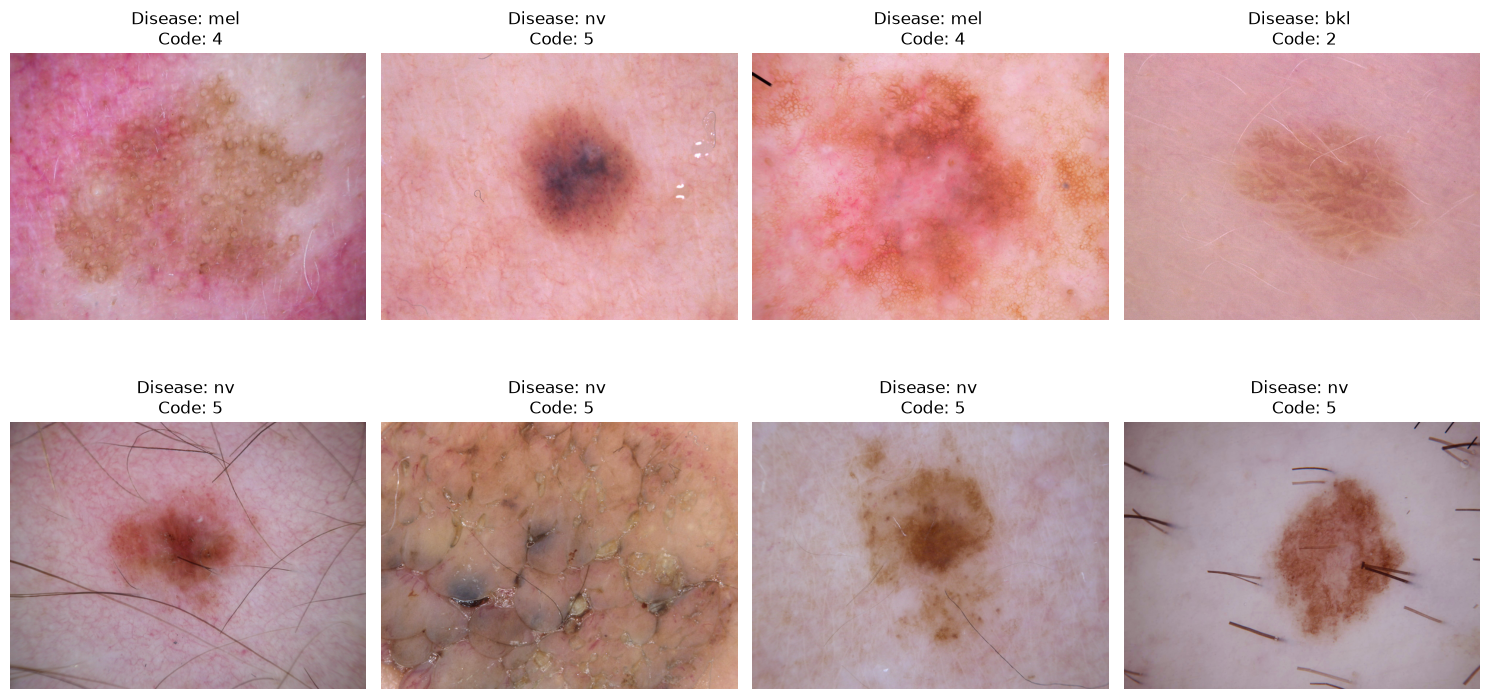

In [5]:
import matplotlib.pyplot as plt
from PIL import Image

# إعداد شكل الشبكة اللي هنعرض فيها الصور (صفين وكل صف فيه 4 صور)
fig, axes = plt.subplots(2, 4, figsize=(15, 8))
axes = axes.flatten()

# اختيار 8 عينات عشوائية من الجدول بتاعنا
sample_df = df.sample(8, random_state=42)

# حلقة تكرارية (Loop) للمرور على الـ 8 عينات وقراءتهم وعرضهم
for i, (index, row) in enumerate(sample_df.iterrows()):
    # قراءة الصورة من المسار بتاعها
    img = Image.open(row['path'])
    
    # عرض الصورة
    axes[i].imshow(img)
    # كتابة التشخيص (اسم المرض) فوق كل صورة
    axes[i].set_title(f"Disease: {row['dx']} \n Code: {row['disease_code']}")
    # إخفاء المحاور (الأرقام اللي على الأطراف) عشان الشكل يكون أنظف
    axes[i].axis('off')

plt.tight_layout()
plt.show()

In [6]:
import cv2
import numpy as np
from sklearn.model_selection import train_test_split

IMG_SIZE = 128

def load_and_resize(path):
    img = cv2.imread(path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, (IMG_SIZE, IMG_SIZE))
    return img

print("جاري معالجة الصور وتوحيد حجمها...")

# تطبيق الدالة على كل مسارات الصور
df['image_data'] = df['path'].map(load_and_resize)

# التعديل هنا: تحويل البيانات لـ float32 لتوفير نص مساحة الرامات تقريباً
X = np.array(df['image_data'].tolist(), dtype=np.float32)

# تفريغ الذاكرة بحذف عمود الصور من الجدول بعد ما نقلناه لـ X
df.drop(columns=['image_data'], inplace=True)

# إجراء عملية القسمة في نفس مكان الذاكرة (In-place)
X /= 255.0 

y = np.array(df['disease_code'])

# تقسيم البيانات (80% تدريب و 20% اختبار)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

print(f"شكل بيانات التدريب: {X_train.shape}")
print(f"شكل بيانات الاختبار: {X_test.shape}")

جاري معالجة الصور وتوحيد حجمها...
شكل بيانات التدريب: (8012, 128, 128, 3)
شكل بيانات الاختبار: (2003, 128, 128, 3)


In [7]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

# بناء هيكل الموديل
model = Sequential([
    Conv2D(32, (3,3), activation='relu', input_shape=(128, 128, 3)),
    MaxPooling2D(2,2),
    
    Conv2D(64, (3,3), activation='relu'),
    MaxPooling2D(2,2),
    
    Conv2D(128, (3,3), activation='relu'),
    MaxPooling2D(2,2),
    
    Flatten(),
    
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(7, activation='softmax') # 7 فئات للأمراض
])

# تجميع الموديل
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# عرض ملخص الهيكل
model.summary()

d:\skinpro\venv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,543 (12.61 MB)

 Trainable params: 3,305,543 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# هنبدأ بـ 10 دورات تدريبية (Epochs) كبداية
EPOCHS = 10

print("بدأنا عملية التدريب...")

# تدريب الموديل وحفظ النتائج في متغير history
history = model.fit(
    X_train, y_train,
    epochs=EPOCHS,
    validation_data=(X_test, y_test),
    batch_size=32
)

بدأنا عملية التدريب...
Epoch 1/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 224s 825ms/step - accuracy: 0.6624 - loss: 1.0534 - val_accuracy: 0.6680 - val_loss: 0.9055
Epoch 2/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 255s 1s/step - accuracy: 0.6739 - loss: 0.9083 - val_accuracy: 0.6770 - val_loss: 0.9349
Epoch 3/10
251/251 ━━━━━━━━━━━━━━━━━━━━ 187s 706ms/step - accuracy: 0.6807 - loss: 0.8787 - val_accuracy: 0.6765 - val_loss: 0.8753
Epoch 4/10
235/251 ━━━━━━━━━━━━━━━━━━━━ 11s 701ms/step - accuracy: 0.6891 - loss: 0.8347

تم حفظ الموديل بنجاح باسم skin_disease_model.h5


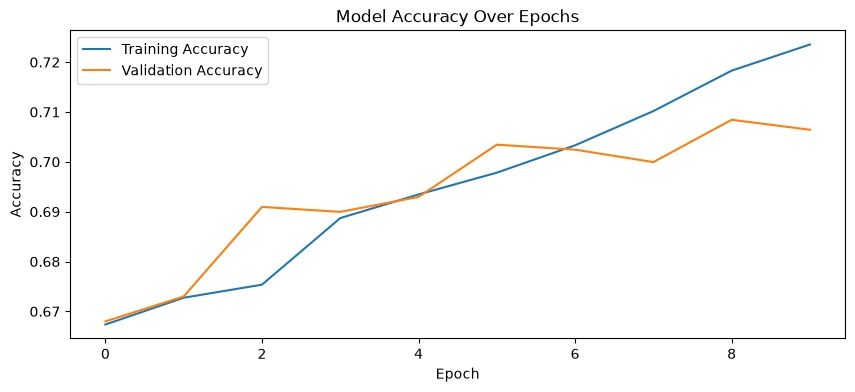

In [ ]:
# حفظ الموديل لاستخدامه لاحقاً في واجهة الويب
model.save('skin_disease_model.h5')
print("تم حفظ الموديل بنجاح باسم skin_disease_model.h5")

# رسم بياني لتطور الدقة
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 4))
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy Over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

# 1. إعداد تقنية توليد الصور (Data Augmentation)
datagen = ImageDataGenerator(
    rotation_range=20,      # تدوير الصورة حتى 20 درجة
    width_shift_range=0.1,  # إزاحة أفقية
    height_shift_range=0.1, # إزاحة رأسية
    zoom_range=0.1,         # تكبير وتصغير
    horizontal_flip=True,   # قلب أفقي
    vertical_flip=True      # قلب رأسي
)
datagen.fit(X_train)

# 2. حساب أوزان الفئات لمعالجة عدم توازن البيانات (Class Imbalance)
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)
class_weight_dict = dict(enumerate(class_weights))

print("أوزان الفئات لتعديل تحيز الموديل:")
print(class_weight_dict)

# 3. إعادة تدريب الموديل مع التوليد والأوزان لـ 20 دورة
EPOCHS = 20
BATCH_SIZE = 32

history_improved = model.fit(
    datagen.flow(X_train, y_train, batch_size=BATCH_SIZE),
    epochs=EPOCHS,
    validation_data=(X_test, y_test),
    class_weight=class_weight_dict,
    steps_per_epoch=len(X_train) // BATCH_SIZE
)

# 4. حفظ الموديل المطور بعد إعادة التدريب
model.save('skin_disease_model.h5')
print("تم حفظ الموديل المطور بنجاح باسم skin_disease_model.h5")


أوزان الفئات لتعديل تحيز الموديل:
{0: np.float64(4.436323366555925), 1: np.float64(2.71869697997964), 2: np.float64(1.3140888961784485), 3: np.float64(13.155993431855501), 4: np.float64(1.2903849251087132), 5: np.float64(0.2132609332162155), 6: np.float64(9.459268004722551)}
Epoch 1/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 250s 984ms/step - accuracy: 0.4456 - loss: 1.7404 - val_accuracy: 0.5027 - val_loss: 1.3987
Epoch 2/20
  1/250 ━━━━━━━━━━━━━━━━━━━━ 3:16 790ms/step - accuracy: 0.3750 - loss: 1.4673

d:\skinpro\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


250/250 ━━━━━━━━━━━━━━━━━━━━ 11s 42ms/step - accuracy: 0.3750 - loss: 1.4673 - val_accuracy: 0.4928 - val_loss: 1.4078
Epoch 3/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 266s 1s/step - accuracy: 0.3216 - loss: 1.8846 - val_accuracy: 0.3999 - val_loss: 1.7746
Epoch 4/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 13s 48ms/step - accuracy: 0.1562 - loss: 1.3692 - val_accuracy: 0.3999 - val_loss: 1.7715
Epoch 5/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 201s 801ms/step - accuracy: 0.3635 - loss: 1.7690 - val_accuracy: 0.4858 - val_loss: 1.4721
Epoch 6/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 11s 42ms/step - accuracy: 0.4375 - loss: 1.5004 - val_accuracy: 0.4938 - val_loss: 1.4381
Epoch 7/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 178s 712ms/step - accuracy: 0.3961 - loss: 1.6301 - val_accuracy: 0.5047 - val_loss: 1.3168
Epoch 8/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 11s 43ms/step - accuracy: 0.4375 - loss: 0.8928 - val_accuracy: 0.5012 - val_loss: 1.3145
Epoch 9/20
250/250 ━━━━━━━━━━━━━━━━━━━━ 187s 747ms/step - accuracy: 0.4076 - loss: 1.5344 - val_ac

تم حفظ الموديل المطور بنجاح باسم skin_disease_model.h5


In [ ]:
import tensorflow as tf
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model

# 1. تحميل معمارية MobileNetV2 المدربة مسبقاً على ملايين الصور
base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(128, 128, 3))

# تجميد الطبقات الأساسية للاستفادة من الميزات الاستخراجية الجاهزة
base_model.trainable = False

# 2. إضافة طبقات التصنيف الخاصة بمشروعنا (7 أمراض)
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dropout(0.3)(x)
x = Dense(128, activation='relu')(x)
predictions = Dense(7, activation='softmax')(x)

model_transfer = Model(inputs=base_model.input, outputs=predictions)

# 3. تجميع الموديل
model_transfer.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

print("بدء تدريب موديل MobileNetV2 الاحترافي...")

# 4. التدريب لـ 15 دورة
history_tl = model_transfer.fit(
    datagen.flow(X_train, y_train, batch_size=32),
    epochs=15,
    validation_data=(X_test, y_test),
    class_weight=class_weight_dict
)

# 5. حفظ الموديل الجديد بنفس الاسم ليستقبله السيرفر
model_transfer.save('skin_disease_model.h5')
print("تم حفظ موديل MobileNetV2 بنجاح باسم skin_disease_model.h5")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 5s 1us/step
بدء تدريب موديل MobileNetV2 الاحترافي...
Epoch 1/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 241s 887ms/step - accuracy: 0.4393 - loss: 1.5930 - val_accuracy: 0.4903 - val_loss: 1.3156
Epoch 2/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 192s 764ms/step - accuracy: 0.5005 - loss: 1.2691 - val_accuracy: 0.5647 - val_loss: 1.0954
Epoch 3/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 190s 759ms/step - accuracy: 0.5339 - loss: 1.2112 - val_accuracy: 0.4918 - val_loss: 1.2669
Epoch 4/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 194s 772ms/step - accuracy: 0.5331 - loss: 1.1422 - val_accuracy: 0.5572 - val_loss: 1.2039
Epoch 5/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 192s 766ms/step - accuracy: 0.5498 - loss: 1.1053 - val_accuracy: 0.5971 - val_loss: 1.0150
Epoch 6/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 192s 768ms/step - accuracy: 0.5543 - loss: 1.0663 - val_accuracy: 0.5432 - val_loss: 1.1725
Epoch 7/15
251/251 ━━━━━━━━━━━━━━━━━━━━ 192s 764ms/step - accuracy: 0.5723 - loss: 1.0523 - val_accuracy: 0.5647 - val

تم حفظ موديل MobileNetV2 بنجاح باسم skin_disease_model.h5
